In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from pathlib import Path
import time, warnings
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi':120, 'font.size':11,
                     'axes.grid':True, 'grid.alpha':0.3})

In [2]:
# ── parameters (edit these to match your run) ────────────────────────────────
N_ATOMS      = 4000
DIM          = 3
N_MODES      = DIM * N_ATOMS - DIM          # 3N - 3 physical modes
L_BOX        = 15.874010519682
V_BOX        = L_BOX**3                     # = 4000.00  (rho = 1)

TEMPERATURES = [0.000001, 0.000005, 0.000010, 0.000015,
                0.000020, 0.000025, 0.000030, 0.000035, 0.000040]
SERIALS      = [0]
SKIP         = 0.30           # discard first 30 % — same as thermal_expansion_lj.ipynb
N_EIGS       = 150            # eigenmodes for Hessian diagonalisation

DATA_DIR     = Path('.')      # folder containing all output files

print(f"N={N_ATOMS}  DIM={DIM}  N_modes={N_MODES}")
print(f"V={V_BOX:.4f}  rho={N_ATOMS/V_BOX:.6f}")

N=4000  DIM=3  N_modes=11997
V=4000.0000  rho=1.000000


In [3]:
elas = np.loadtxt(DATA_DIR / "snp_elasticity_N4000_z16.24_s000.dat", comments="#")
if elas.ndim == 1:
    elas = elas[np.newaxis, :]

# columns: serial  P0  K_born  K_na  K  mu_born  mu_na  mu
serials  = elas[:, 0].astype(int)
P0_arr   = elas[:, 1]
K_born_a = elas[:, 2]
K_na_a   = elas[:, 3]
K_arr    = elas[:, 4]
mu_arr   = elas[:, 7]

K_per_net  = {serials[i]: K_arr[i]  for i in range(len(serials))}

print(f"{'Serial':>8}  {'P0':>12}  {'K_born':>10}  {'K_na':>10}  {'K':>10}  {'mu':>8}")
print("-" * 60)
for i in range(len(serials)):
    print(f"{int(serials[i]):>8}  {P0_arr[i]:>12.3e}  "
          f"{K_born_a[i]:>10.5f}  {K_na_a[i]:>10.5f}  "
          f"{K_arr[i]:>10.5f}  {mu_arr[i]:>8.5f}")

  Serial            P0      K_born        K_na           K        mu
------------------------------------------------------------
       0     0.000e+00    13.66291     1.04562     1.40192   0.83471
       0     0.000e+00    13.66291     1.04562     1.40192   0.83471
       0     0.000e+00    13.66291     1.04562     1.40192   0.83471
       0     0.000e+00    13.66291     1.04562     1.40192   0.83471
       0     0.000e+00    13.66291     1.04562     1.40192   0.83471


In [4]:
def read_nvt(filepath, skip=SKIP):
    # SOURCE: thermal_expansion_lj.ipynb::read_nvt() -- identical
    d = np.loadtxt(filepath, comments="#")
    n = int(len(d) * skip)
    prod = d[n:]
    T_meas = (2. / 3.) * prod[:, 1].mean()   # kinetic equipartition
    P_mean = prod[:, 3].mean()
    P_err  = prod[:, 3].std() / np.sqrt(len(prod))
    return T_meas, P_mean, P_err

pg_data = {g: [] for g in SERIALS}

print(f"{'T_set':>12}  {'T_meas':>12}  {'P_vir':>14}  {'err':>10}")
print("-" * 54)
for g in SERIALS:
    for T in TEMPERATURES:
        f = DATA_DIR / f"snp_NVT_T{T:.6f}_s{g}.dat"
        if f.exists():
            Tm, Pm, Pe = read_nvt(f)
            pg_data[g].append((Tm, Pm, Pe))
            print(f"{T:>12.6f}  {Tm:>12.6f}  {Pm:>14.8f}  {Pe:>10.2e}")
        else:
            print(f"{T:>12.6f}  -- file not found: {f.name}")

       T_set        T_meas           P_vir         err
------------------------------------------------------
    0.000001      0.000001     -0.00000209    2.06e-07
    0.000005      0.000005     -0.00001012    4.43e-07
    0.000010      0.000010     -0.00002130    6.19e-07
    0.000015      0.000015     -0.00003347    8.34e-07
    0.000020      0.000020     -0.00004186    9.29e-07
    0.000025      0.000025     -0.00005417    1.06e-06
    0.000030      0.000030     -0.00006756    1.11e-06
    0.000035      0.000035     -0.00007954    1.21e-06
    0.000040      0.000040     -0.00008850    1.23e-06


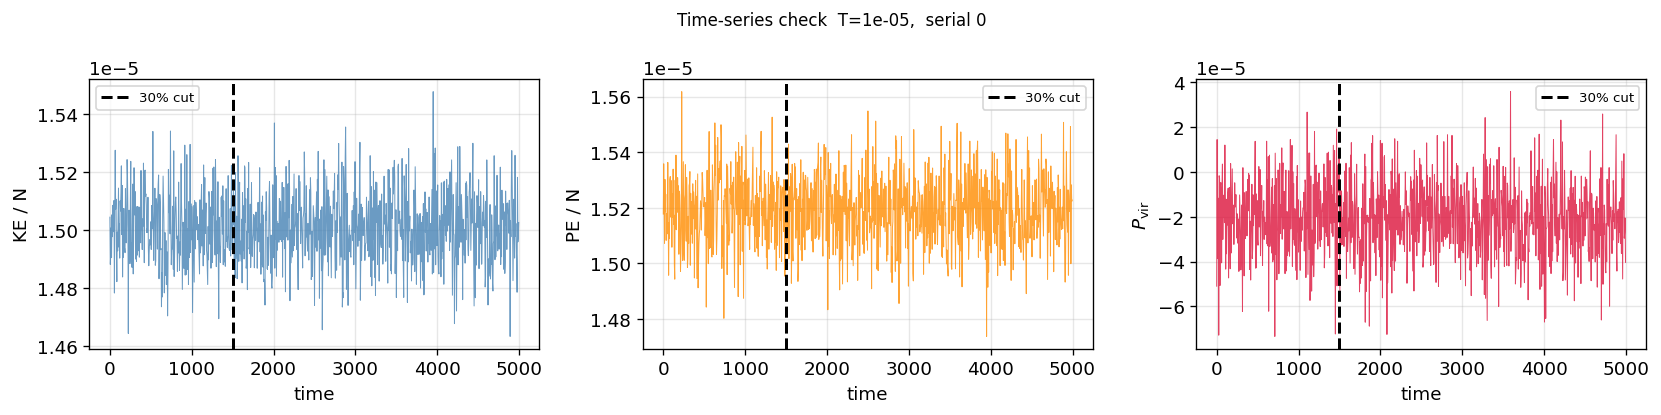

In [5]:
g0 = SERIALS[0]
T0 = TEMPERATURES[2] # pick a temperature to plot time-series data
fc = DATA_DIR / f"snp_NVT_T{T0:.6f}_s{g0}.dat"

if fc.exists():
    dc = np.loadtxt(fc, comments="#")
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
    for ax, (col, lab, c) in zip(axes, [
            (1, 'KE / N',              'steelblue'),
            (2, 'PE / N',              'darkorange'),
            (3, r'$P_\mathrm{vir}$', 'crimson')]):
        ax.plot(dc[:, 0], dc[:, col], lw=0.6, color=c, alpha=0.8)
        ns = int(len(dc) * SKIP)
        ax.axvline(dc[ns, 0], color='k', ls='--', lw=1.8, label='30% cut')
        ax.set_xlabel('time'); ax.set_ylabel(lab)
        ax.legend(fontsize=8)
    fig.suptitle(f'Time-series check  T={T0},  serial {g0}', fontsize=10)
    fig.tight_layout()
    plt.show()

In [6]:
def weighted_linear_fit(T_vals, P_vals, P_errs):
    # SOURCE: thermal_expansion_lj.ipynb::weighted_linear_fit() -- identical
    w = 1. / np.array(P_errs)**2
    A = np.column_stack([np.ones_like(T_vals), T_vals])
    M = A.T @ np.diag(w) @ A
    c = np.linalg.solve(M, A.T @ (w * np.array(P_vals)))
    e = np.sqrt(np.diag(np.linalg.inv(M)))
    return c[0], c[1], e[0], e[1]

alpha_num = {}
pg_fit    = {}

print(f"{'Serial':>8}  {'K':>8}  {'P0_fit':>12}  "
      f"{'dP/dT':>12}  {'dPdT_err':>10}  {'alpha_num':>12}")
print("-" * 68)

for g in SERIALS:
    pts = pg_data[g]
    if len(pts) < 3:
        print(f"  serial {g}: only {len(pts)} points — skipping"); continue
    Tv = np.array([p[0] for p in pts])
    Pv = np.array([p[1] for p in pts])
    Ev = np.array([p[2] for p in pts])
    a, b, ea, eb = weighted_linear_fit(Tv, Pv, Ev)
    Kg = K_per_net[g]
    an = b / Kg
    pg_fit[g]   = (a, b, ea, eb)
    alpha_num[g] = an
    print(f"{g:>8}  {Kg:>8.5f}  {a:>12.4e}  "
          f"{b:>12.6f}  {eb:>10.6f}  {an:>+12.6e}")

  Serial         K        P0_fit         dP/dT    dPdT_err     alpha_num
--------------------------------------------------------------------
       0   1.40192    3.3524e-07     -2.218453    0.017940  -1.582437e+00


In [7]:
import os
import glob
from datetime import datetime

print(f"Jupyter thinks the current folder is: {os.getcwd()}")

files = glob.glob('snp_NVT_T*.dat')
if files:
    f = files[0]
    print(f"Reading file: {os.path.abspath(f)}")
    print(f"File was last modified: {datetime.fromtimestamp(os.path.getmtime(f))}")
    with open(f, 'r') as file:
        print("First line of data:", file.readlines()[1].strip())
else:
    print("NO NVT FILES FOUND IN JUPYTER'S FOLDER!")

Jupyter thinks the current folder is: /home/sangam/vsc/glass_simulations/spring_networks/new
Reading file: /home/sangam/vsc/glass_simulations/spring_networks/new/snp_NVT_T0.000010_s0.dat
File was last modified: 2026-06-17 17:57:42.215059
First line of data: 0	1.5044856e-05	1.5177636e-05	-5.0963618e-05


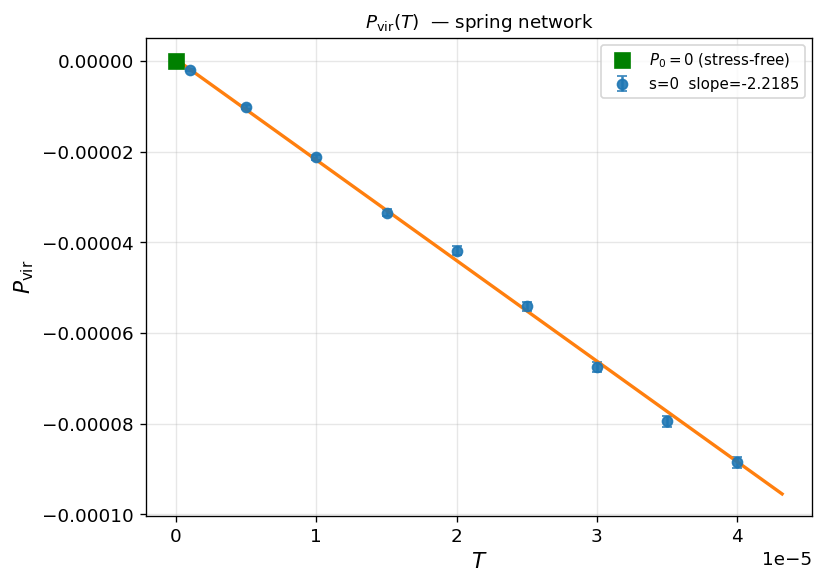

In [8]:
# ── P(T) plot ─────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))

for g in SERIALS:
    if g not in pg_fit: continue
    pts = pg_data[g]
    Tv  = np.array([p[0] for p in pts])
    Pv  = np.array([p[1] for p in pts])
    Ev  = np.array([p[2] for p in pts])
    a, b, _, _ = pg_fit[g]
    Tl = np.linspace(0, Tv.max() * 1.08, 200)
    ax.errorbar(Tv, Pv, yerr=Ev, fmt='o', ms=6, capsize=3,
                alpha=0.9, label=f's={g}  slope={b:.4f}')
    ax.plot(Tl, a + b * Tl, '-', lw=2)

ax.plot(0, 0, 'gs', ms=9, zorder=5, label=r'$P_0 = 0$ (stress-free)')
ax.set_xlabel(r'$T$', fontsize=13)
ax.set_ylabel(r'$P_\mathrm{vir}$', fontsize=13)
ax.set_title(r'$P_\mathrm{vir}(T)$  — spring network', fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('fig1_P_vs_T.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
"""
dP/dT theory  (Eq. 21/22 of PDF)  --  C-delegated, v4
======================================================

WORKFLOW:
  1. Diagonalise hessian_g{g}.txt (scipy.linalg.eigh, dense, same cost as before).
  2. Strip near-zero modes (3 translations), write
         eigvecs_g{g}.bin   -- n_modes × DOFS float64 blocks, one block per mode
         eigvals_g{g}.txt   -- n_modes lines of omega^2
  3. Shell out to the v4 C binary (pass 2):
         ./dPdT_v4  <network_file>  <glass_idx>  eigvecs_g{g}.bin
     which recomputes vna_eta = -H^-1 . xi_eta_x and, per mode Psi_omega:
         term1 = u_eta_x_x_on_two_vectors(Psi, Psi)           [Eq.20, harmonic]
         term2 = cdot(vna_eta, tessianOnTwoVectors(Psi, Psi))  [Eq.21, anharmonic]
             --> algebraically = tessianOnThreeVectors(vna_eta, Psi, Psi)
                 but computed via the two-pass (tessianOnTwoVectors then cdot)
                 form to avoid reimplementing bond loops in Python.
     Outputs:
         mode_terms_g{g}.txt      per-mode (term1, term2), unweighted
         dPdT_results_g{g}.txt    columns:
               harm  anh  2*(dP/dT)_V  (dP/dT)_V  V
     where (Eq.21/22, with pre = -1/(V*DIM)):
               harm = pre * sum_omega term1/omega^2
               anh  = pre * sum_omega term2/omega^2
               2*(dP/dT)_V = harm + anh
  4. Read dPdT_results_g{g}.txt, compute alpha_theory = (dP/dT)_V / K,
     compare with alpha_numerical from the linear P(T) fit above.

Python NEVER reimplements tessianOnTwoVectors, cdot, or u_eta_x_x_on_two_vectors.
All bond-loop tensor contractions live entirely in 3D_spring_network_dPdT_test_v4.c.
"""

import os, subprocess
import numpy as np
import scipy.sparse as sp
import scipy.linalg

# ── configuration ─────────────────────────────────────────────────────────────
# Path to the binary compiled from 3D_spring_network_dPdT_test_v4.c:
#   gcc -O2 -o dPdT_v4 3D_spring_network_dPdT_test_v4.c -lm
C_BINARY         = "./dPdT_v4"

# Network file for the glass being analysed (fed to C as argv[1])
def network_file(g):
    return str(DATA_DIR / f"network_N{N_ATOMS}_z16.24_s{g:04d}.dat")

GLASS_IDX        = SERIALS[0]       # change to any serial from SERIALS
ZERO_MODE_CUTOFF = 1e-4             # omega^2 cutoff for near-zero mode removal


# ── Step 1 & 2: diagonalise H, write eigvec/eigenvalue files ─────────────────
def diagonalise_and_write(g):
    """
    Loads hessian_g{g}.txt, calls scipy.linalg.eigh (LAPACK dsyevd on the
    full dense DOFS×DOFS matrix), strips near-zero modes, then writes:
        eigvecs_g{g}.bin  -- (n_valid, DOFS) float64, C-contiguous
                             (n_valid back-to-back DOFS-length blocks;
                              block m = eigenvector of mode m)
        eigvals_g{g}.txt  -- n_valid lines, one omega^2 per line, same order
    """
    DOFS = N_ATOMS * DIM

    # -- load sparse Hessian --------------------------------------------------
    fname = DATA_DIR / f"hessian_g{g}.txt"
    print(f"  loading {fname.name} ...", flush=True)
    raw  = np.loadtxt(str(fname))
    rows = raw[:, 0].astype(np.int32)
    cols = raw[:, 1].astype(np.int32)
    vals = raw[:, 2]
    H    = sp.csr_matrix((vals, (rows, cols)), shape=(DOFS, DOFS))

    # -- dense diagonalisation ------------------------------------------------
    print(f"  [g={g}] converting sparse H to dense {DOFS}×{DOFS} ...", flush=True)
    H_dense = H.toarray()
    print(f"  [g={g}] scipy.linalg.eigh (LAPACK dsyevd) ...", flush=True)
    evals, evecs = scipy.linalg.eigh(H_dense)
    del H_dense

    # -- strip near-zero (translation) modes ----------------------------------
    valid       = evals > ZERO_MODE_CUTOFF
    valid_evals = evals[valid]
    valid_evecs = evecs[:, valid]    # shape (DOFS, n_valid)
    n_valid     = valid_evals.size
    print(f"  [g={g}] {n_valid} physical modes "
          f"({DOFS - n_valid} near-zero stripped)", flush=True)

    # -- write binary eigvec block --------------------------------------------
    evec_path = DATA_DIR / f"eigvecs_g{g}.bin"
    eval_path = DATA_DIR / f"eigvals_g{g}.txt"
    # valid_evecs.T  is (n_valid, DOFS); tofile() writes row-major -> n_valid
    # back-to-back DOFS-length float64 blocks, exactly what write_mode_terms_text
    # reads with fread(Psi, sizeof(double), DOFS, fin).
    valid_evecs.T.astype(np.float64).tofile(str(evec_path))
    np.savetxt(str(eval_path), valid_evals)
    print(f"  wrote {evec_path.name}  ({n_valid} × {DOFS} float64, "
          f"{evec_path.stat().st_size/1e6:.1f} MB)", flush=True)
    print(f"  wrote {eval_path.name}", flush=True)
    return n_valid


# ── Step 3: C pass 2 -- bond-loop contractions per mode ──────────────────────
def run_c_mode_terms(g):
    """
    Invokes:  ./dPdT_v4  <network_file>  <glass_idx>  eigvecs_g{g}.bin

    This triggers the mode-terms pass added in v4 main() (argc > 3 branch):
      - reads the network, recomputes vna_eta = -H^-1 . xi_eta_x via CG,
      - reads eigvecs_g{g}.bin + eigvals_g{g}.txt,
      - for each mode calls mode_terms(Psi, vna_eta, tmp, &t1, &t2):
            term1 = u_eta_x_x_on_two_vectors(Psi, Psi)
            term2 = cdot(vna_eta, tessianOnTwoVectors(Psi, Psi))
      - writes mode_terms_g{g}.txt  and  dPdT_results_g{g}.txt.
    """
    evecs_path = str(DATA_DIR / f"eigvecs_g{g}.bin")
    cmd = [C_BINARY, network_file(g), str(g), evecs_path]
    print(f"\n  running: {' '.join(cmd)}", flush=True)
    result = subprocess.run(cmd, capture_output=True, text=True)
    for line in result.stdout.strip().split('\n'):
        print("    [C] " + line)
    if result.returncode != 0:
        print(f"  ERROR: C binary exited with code {result.returncode}")
        if result.stderr:
            print(result.stderr)
        return False
    return True


# ── Step 4: read results & compare ───────────────────────────────────────────
def read_dPdT_results(g):
    """
    Reads dPdT_results_g{g}.txt (written by C write_mode_terms_text()).
    Columns: harm  anh  2*(dP/dT)_V  (dP/dT)_V  V
    """
    fname = DATA_DIR / f"dPdT_results_g{g}.txt"
    arr   = np.loadtxt(str(fname), comments='#')
    return arr   # (harm, anh, two_dPdT, dPdT, V)


# ── driver ────────────────────────────────────────────────────────────────────
print("=" * 65)
print("  dP/dT theory  (Eq.21/22)  --  C-delegated, v4")
print(f"  glass index  : {GLASS_IDX}")
print(f"  C binary     : {C_BINARY}")
print(f"  data dir     : {DATA_DIR}")
print("=" * 65)

g = GLASS_IDX

# -- Step 1+2: diagonalise unless eigvecs already on disk --------------------
evec_path = DATA_DIR / f"eigvecs_g{g}.bin"
eval_path = DATA_DIR / f"eigvals_g{g}.txt"
if evec_path.exists() and eval_path.exists():
    n_existing = int(np.loadtxt(str(eval_path)).size)
    print(f"  eigvecs/eigvals already on disk ({n_existing} modes) -- "
          f"skipping diagonalisation")
    print(f"  (delete {evec_path.name} + {eval_path.name} to re-diagonalise)")
else:
    diagonalise_and_write(g)

# -- Step 3: C mode-terms pass -----------------------------------------------
ok = run_c_mode_terms(g)

# -- Step 4: display & compare -----------------------------------------------
if ok:
    harm, anh, two_dPdT, dPdT, V_c = read_dPdT_results(g)

    K_g = K_per_net.get(g, None)
    alpha_theory = dPdT / K_g if K_g else None

    print("\n" + "=" * 65)
    print(f"  V                         = {V_c:.6f}")
    print(f"  harmonic   contribution   = {harm:+.6e}   [-(1/VD) sum term1/w^2]")
    print(f"  anharmonic contribution   = {anh:+.6e}   [-(1/VD) sum term2/w^2]")
    print(f"  2*(dP/dT)_V  (Eq.21 LHS) = {two_dPdT:+.6e}")
    print(f"  (dP/dT)_V    (Eq.22 LHS) = {dPdT:+.6e}")

    if K_g is not None:
        print(f"\n  K (from snp_elasticity)   = {K_g:.6f}")
        print(f"  alpha_theory = dPdT/K     = {alpha_theory:+.6e}")

    if g in alpha_num:
        an    = alpha_num[g]
        ratio = alpha_theory / an if (alpha_theory and an != 0) else float('nan')
        print(f"  alpha_numerical           = {an:+.6e}")
        print(f"  theory / numerical        = {ratio:.4f}")
    print("=" * 65)
    print("\nFiles written by C pass 2:")
    print(f"  mode_terms_g{g}.txt       per-mode (term1, term2) unweighted")
    print(f"  dPdT_results_g{g}.txt     harm, anh, 2*(dP/dT)_V, (dP/dT)_V, V")


  dP/dT theory  (Eq.21/22)  --  C-delegated, v4
  glass index  : 0
  C binary     : ./dPdT_v4
  data dir     : .
  eigvecs/eigvals already on disk (11997 modes) -- skipping diagonalisation
  (delete eigvecs_g0.bin + eigvals_g0.txt to re-diagonalise)

  running: ./dPdT_v4 network_N4000_z16.24_s0000.dat 0 eigvecs_g0.bin
    [C] Mode-terms pass: eigvecs_g0.bin, glass 0
    [C]   computing vna_eta = -H^-1.xi_eta_x ...
    [C]   eigvecs_g0.bin : 11997 modes x DOFS=12000 (1151.712 MB)
    [C]     mode 2000/11997
    [C]     mode 4000/11997
    [C]     mode 6000/11997
    [C]     mode 8000/11997
    [C]     mode 10000/11997
    [C]   wrote mode_terms_g0.txt (11997 modes)
    [C]   harmonic   contribution = -4.915796e-01
    [C]   anharmonic contribution = +1.263316e-01
    [C]   2*(dp/dT)_V (Eq.21 LHS) = -3.652480e-01
    [C]   (dp/dT)_V   (Eq.22 LHS) = -1.826240e-01
    [C]   wrote dPdT_results_g0.txt
    [C] Mode-terms pass done. Elapsed: 6 s

  V                         = 4000.000000
  har